### SETUP

In [1]:
from pathlib import Path
# --- CELLA 1: SETUP E CARICAMENTO ---

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import warnings
import numpy as np

# Impostazioni standard per i grafici
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 7) # Dimensioni standard per i grafici singoli
warnings.filterwarnings('ignore', category=FutureWarning) # Ignora avvisi futuri di Seaborn

FIG_DIR = Path('figure_eda')
FIG_DIR.mkdir(exist_ok=True)

# Carica i dati puliti (il nostro punto di partenza)
try:
    df_movimento = pd.read_csv('../data/puliti/movimento_puliti.csv')
    df_portieri = pd.read_csv('../data/puliti/portieri_puliti.csv')
    
    print("--- Dati Caricati Correttamente ---")
    print(f"Giocatori di Movimento: {df_movimento.shape}")
    print(f"Portieri: {df_portieri.shape}")

except FileNotFoundError:
    print("--- ERRORE ---")
    print("File 'movimento_puliti.csv' o 'portieri_puliti.csv' non trovati.")
    print("Assicurati di aver eseguito il notebook di pulizia e salvataggio.")

# Funzione condivisa dai confronti individuali tra giocatori
def select_player(player_name):
    matches = df_movimento.loc[df_movimento['Name'].eq(player_name)]
    if len(matches) != 1:
        raise ValueError(
            f"Atteso un solo giocatore chiamato '{player_name}', "
            f"ma ne sono stati trovati {len(matches)}."
        )
    return matches.iloc[0]

--- Dati Caricati Correttamente ---
Giocatori di Movimento: (15738, 49)
Portieri: (1999, 19)


### STATISTICHE DI BASE

In [2]:
# --- CELLA 2: STATISTICHE DI BASE (.describe) ---

print("--- Statistiche Base (Giocatori di Movimento) ---")
stats_movimento = ['OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY', 'Age', 'Weak foot', 'Skill moves']
print(df_movimento[stats_movimento].describe().round(1))

print("\n\n--- Statistiche Base (Portieri) ---")
stats_portieri = ['OVR', 'GK Diving', 'GK Handling', 'GK Kicking', 'GK Reflexes', 'GK Speed','GK Positioning', 'Age', 'Weak foot', 'Skill moves']
print(df_portieri[stats_portieri].describe().round(1))

--- Statistiche Base (Giocatori di Movimento) ---
           OVR      PAC      SHO      PAS      DRI      DEF      PHY      Age  \
count  15738.0  15738.0  15738.0  15738.0  15738.0  15738.0  15738.0  15738.0   
mean      67.0     68.5     53.7     58.7     63.9     53.2     65.6     25.6   
std        6.9     10.9     14.1     10.0      9.5     16.1      9.6      4.5   
min       47.0     29.0     20.0     25.0     29.0     15.0     32.0     17.0   
25%       63.0     62.0     43.0     52.0     59.0     40.0     59.0     22.0   
50%       67.0     69.0     56.0     59.0     65.0     58.0     67.0     25.0   
75%       71.0     76.0     64.0     65.0     70.0     65.0     73.0     29.0   
max       91.0     97.0     93.0     94.0     92.0     91.0     91.0     43.0   

       Weak foot  Skill moves  
count    15738.0      15738.0  
mean         3.0          2.6  
std          0.7          0.7  
min          1.0          2.0  
25%          3.0          2.0  
50%          3.0          2.

### DISTRIBUZIONI PRINCIPALI

Visualizzazione grafici distribuzione PAC e Riflessi...


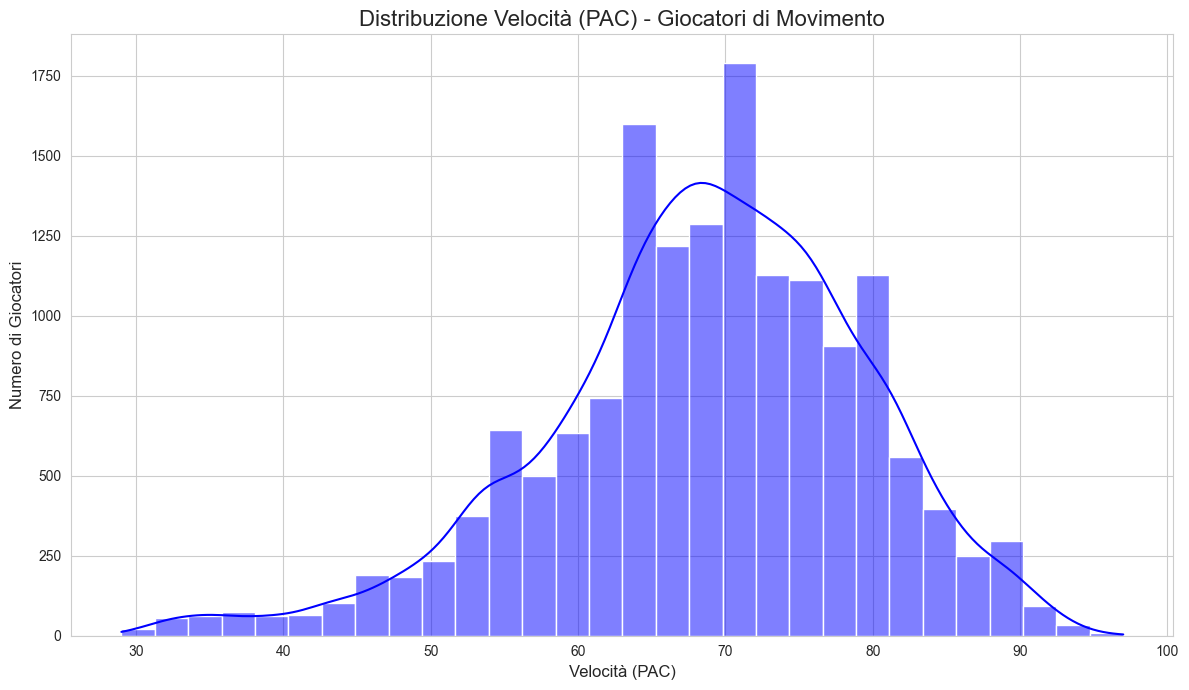

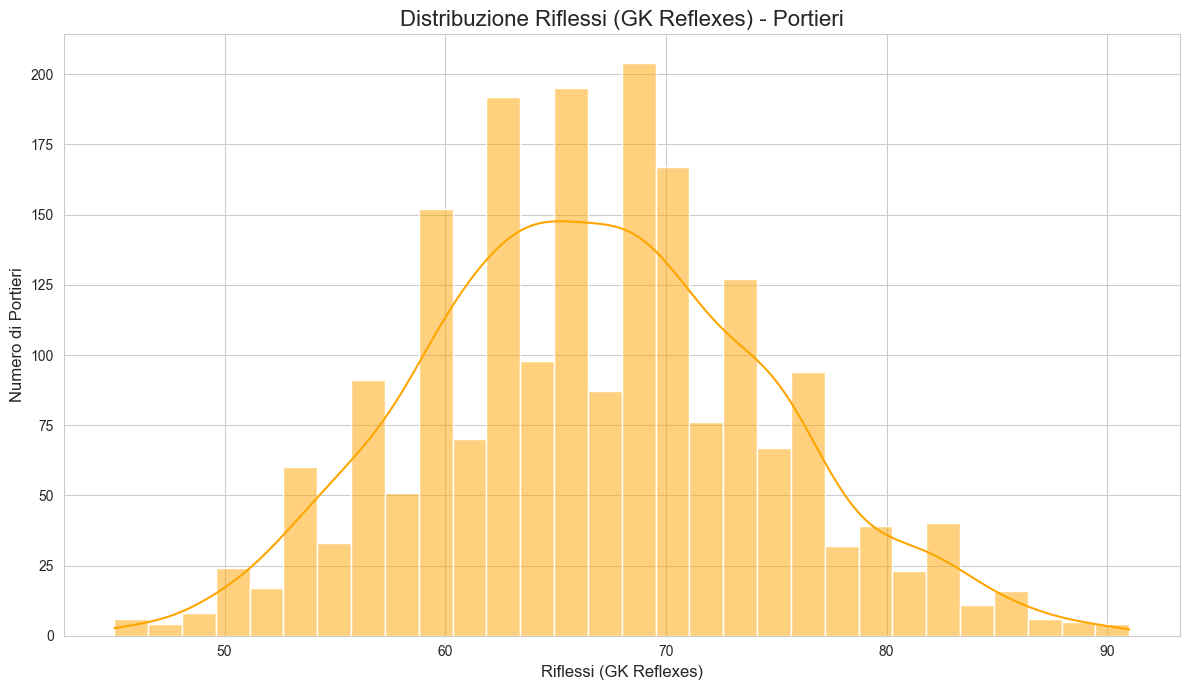

In [3]:
# --- CELLA 3: ISTOGRAMMI (PAC & GK REFLEXES) ---

print("Visualizzazione grafici distribuzione PAC e Riflessi...")

# Grafico 1: Distribuzione Velocità (PAC) - Giocatori di Movimento
plt.figure() # Crea una nuova figura
sns.histplot(df_movimento['PAC'], kde=True, bins=30, color='blue') 
plt.title('Distribuzione Velocità (PAC) - Giocatori di Movimento', fontsize=16)
plt.xlabel('Velocità (PAC)', fontsize=12)
plt.ylabel('Numero di Giocatori', fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / '06_distribuzione_pac_movimento.png', dpi=300, bbox_inches='tight')
plt.show()

# Grafico 2: Distribuzione Riflessi (GK Reflexes) - Portieri
plt.figure() # Crea una nuova figura
sns.histplot(df_portieri['GK Reflexes'], kde=True, bins=30, color='orange')
plt.title('Distribuzione Riflessi (GK Reflexes) - Portieri', fontsize=16)
plt.xlabel('Riflessi (GK Reflexes)', fontsize=12)
plt.ylabel('Numero di Portieri', fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / '07_distribuzione_riflessi_portieri.png', dpi=300, bbox_inches='tight')
plt.show()

Visualizzazione grafici distribuzione Tiro, Difesa e Rinvio...


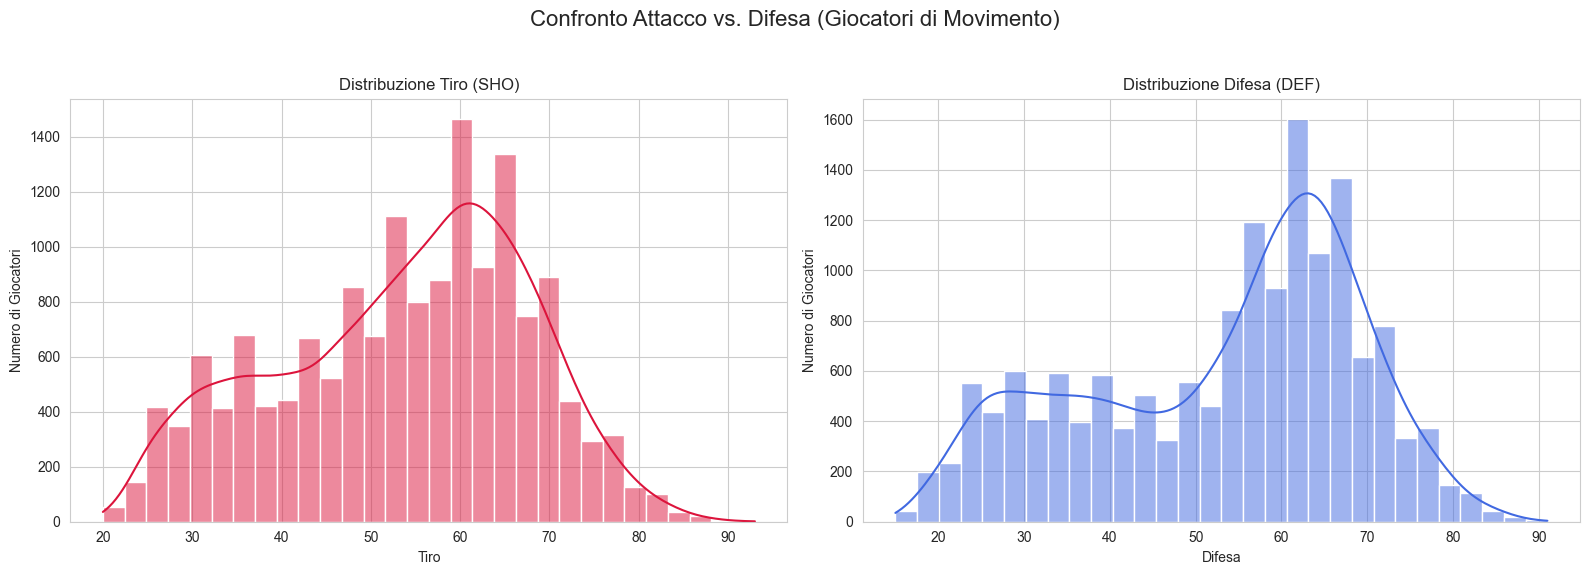

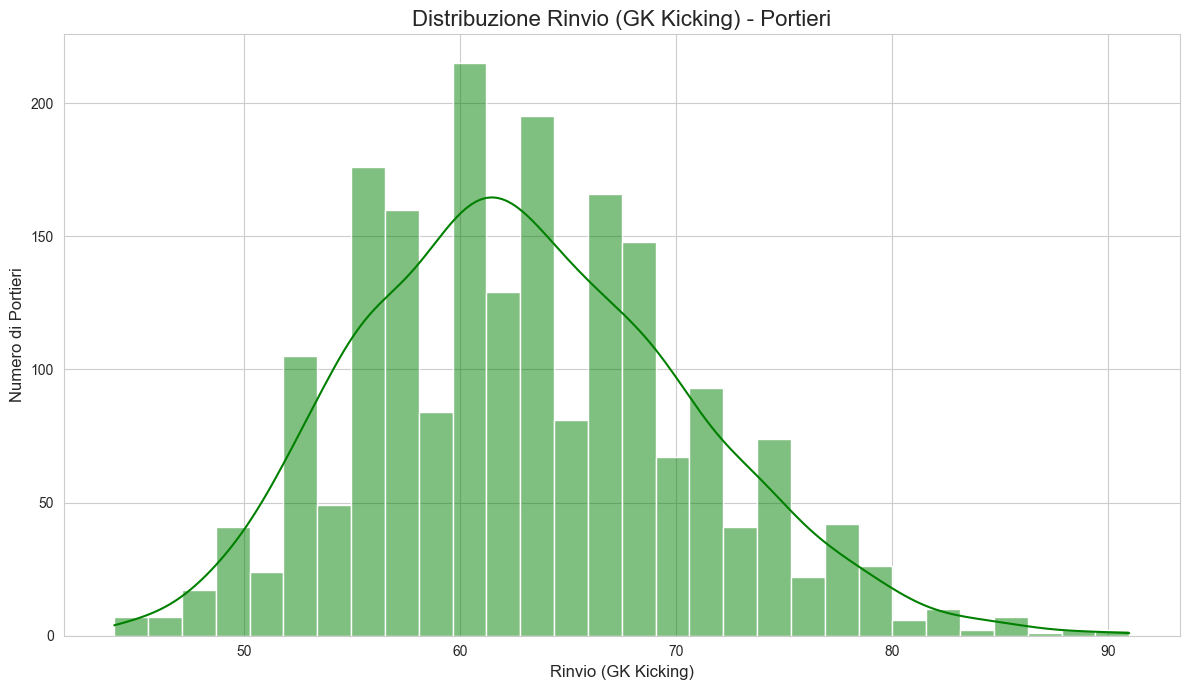

In [4]:
# --- CELLA 4: ISTOGRAMMI (SHO, DEF & GK KICKING) ---

print("Visualizzazione grafici distribuzione Tiro, Difesa e Rinvio...")

# Grafico 3 & 4: Confronto Tiro vs. Difesa (Giocatori di Movimento)
# Usiamo i subplots per metterli fianco a fianco
fig, axes = plt.subplots(1, 2, figsize=(16, 6)) # 1 riga, 2 colonne
fig.suptitle('Confronto Attacco vs. Difesa (Giocatori di Movimento)', fontsize=16)

# Grafico 3: Tiro (SHO)
sns.histplot(df_movimento['SHO'], kde=True, bins=30, ax=axes[0], color='crimson')
axes[0].set_title('Distribuzione Tiro (SHO)')
axes[0].set_xlabel('Tiro')
axes[0].set_ylabel('Numero di Giocatori')

# Grafico 4: Difesa (DEF)
sns.histplot(df_movimento['DEF'], kde=True, bins=30, ax=axes[1], color='royalblue')
axes[1].set_title('Distribuzione Difesa (DEF)')
axes[1].set_xlabel('Difesa')
axes[1].set_ylabel('Numero di Giocatori')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Aggiusta la spaziatura per il titolo
fig.savefig(FIG_DIR / '08_confronto_tiro_difesa_movimento.png', dpi=300, bbox_inches='tight')
plt.show()

# Grafico 5: Distribuzione Rinvio (GK Kicking) - Portieri
plt.figure() # Nuova figura
sns.histplot(df_portieri['GK Kicking'], kde=True, bins=30, color='green')
plt.title('Distribuzione Rinvio (GK Kicking) - Portieri', fontsize=16)
plt.xlabel('Rinvio (GK Kicking)', fontsize=12)
plt.ylabel('Numero di Portieri', fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / '09_distribuzione_rinvio_portieri.png', dpi=300, bbox_inches='tight')
plt.show()

### SKILL E PIEDE DEBOLE

Visualizzazione grafici Skill Moves e Piede Debole...


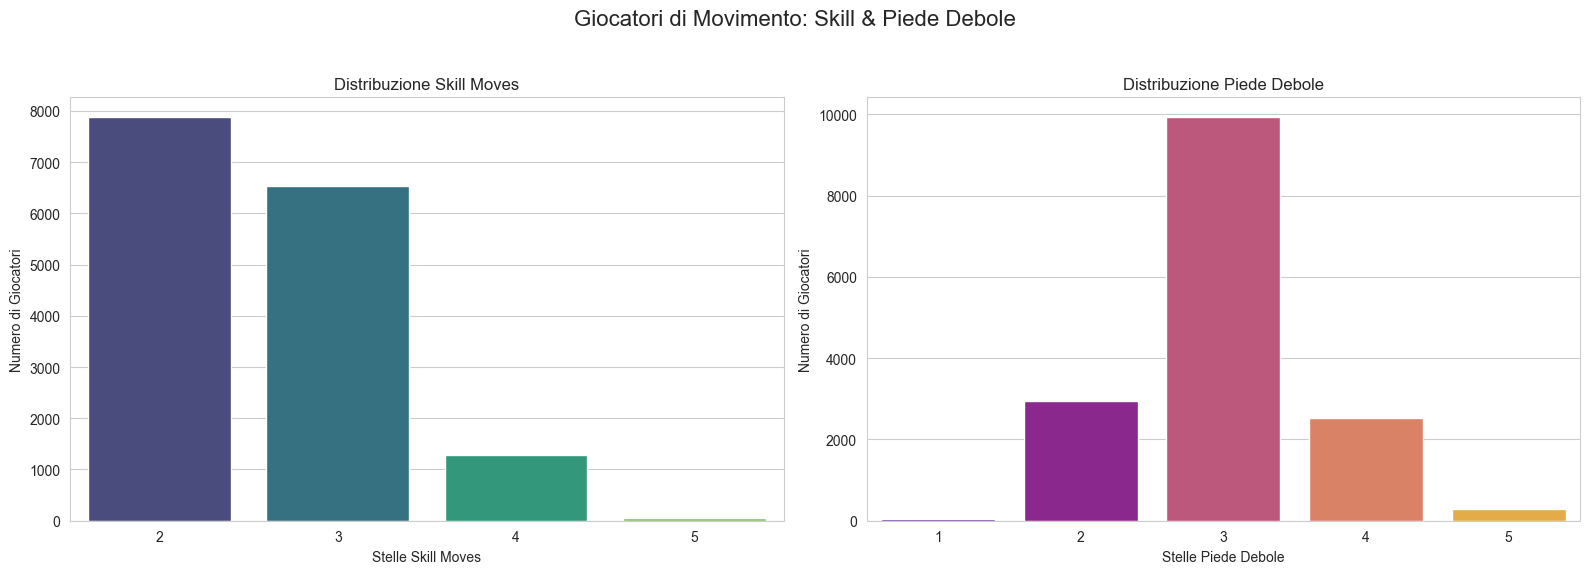

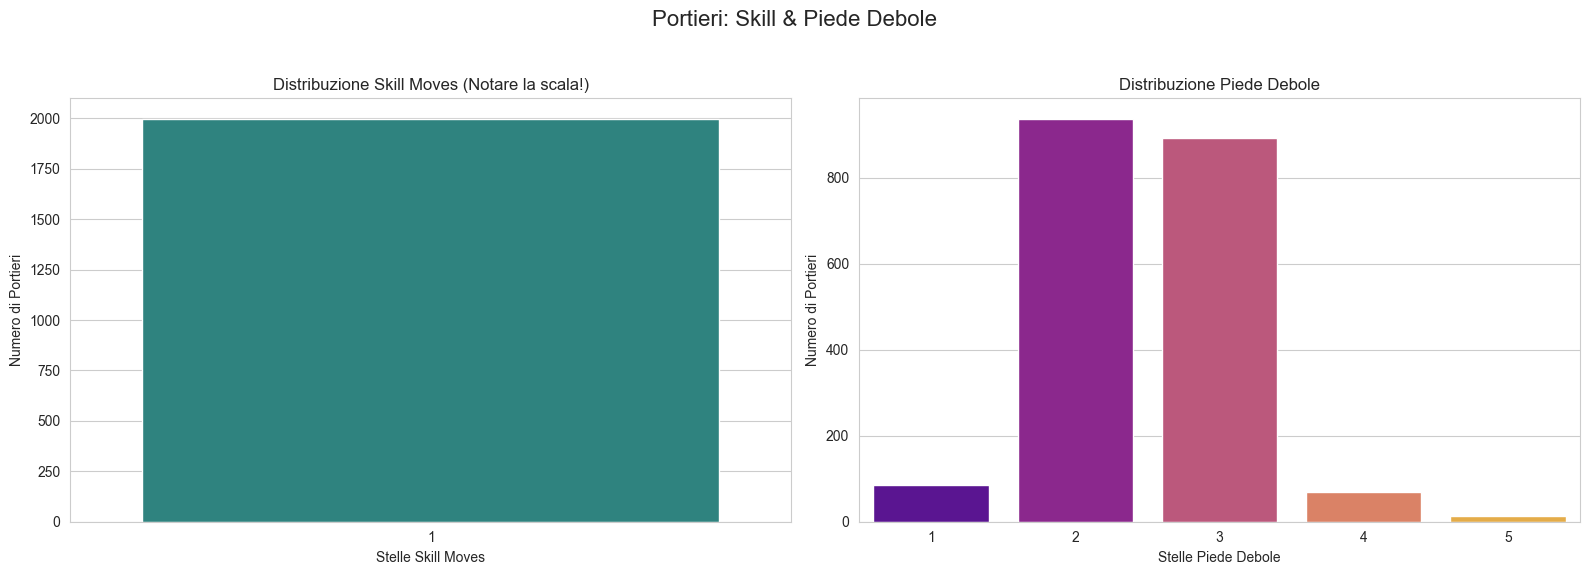

In [5]:
# --- CELLA 5: GRAFICI A BARRE (SKILL MOVES & WEAK FOOT) ---

print("Visualizzazione grafici Skill Moves e Piede Debole...")

# Grafico 6 & 7: Giocatori di Movimento
fig_mov, axes_mov = plt.subplots(1, 2, figsize=(16, 6))
fig_mov.suptitle('Giocatori di Movimento: Skill & Piede Debole', fontsize=16)

sns.countplot(data=df_movimento, x='Skill moves', ax=axes_mov[0], palette='viridis')
axes_mov[0].set_title('Distribuzione Skill Moves')
axes_mov[0].set_xlabel('Stelle Skill Moves')
axes_mov[0].set_ylabel('Numero di Giocatori')

sns.countplot(data=df_movimento, x='Weak foot', ax=axes_mov[1], palette='plasma')
axes_mov[1].set_title('Distribuzione Piede Debole')
axes_mov[1].set_xlabel('Stelle Piede Debole')
axes_mov[1].set_ylabel('Numero di Giocatori')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig_mov.savefig(FIG_DIR / '10_skill_piede_debole_movimento.png', dpi=300, bbox_inches='tight')
plt.show()

# Grafico 8 & 9: Portieri
fig_gk, axes_gk = plt.subplots(1, 2, figsize=(16, 6))
fig_gk.suptitle('Portieri: Skill & Piede Debole', fontsize=16)

sns.countplot(data=df_portieri, x='Skill moves', ax=axes_gk[0], palette='viridis')
axes_gk[0].set_title('Distribuzione Skill Moves (Notare la scala!)')
axes_gk[0].set_xlabel('Stelle Skill Moves')
axes_gk[0].set_ylabel('Numero di Portieri')

sns.countplot(data=df_portieri, x='Weak foot', ax=axes_gk[1], palette='plasma')
axes_gk[1].set_title('Distribuzione Piede Debole')
axes_gk[1].set_xlabel('Stelle Piede Debole')
axes_gk[1].set_ylabel('Numero di Portieri')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig_gk.savefig(FIG_DIR / '11_skill_piede_debole_portieri.png', dpi=300, bbox_inches='tight')
plt.show()

### CORRELAZIONI TRA LE STATISTICHE

Le matrici mostrano il coefficiente di correlazione lineare di Pearson. Tutti i grafici utilizzano la stessa scala da −1 a +1: il rosso indica una relazione positiva, il blu una relazione negativa e i colori vicini al bianco una relazione lineare debole. Una correlazione non implica un rapporto di causa-effetto.


Attaccanti considerati: 3,210
Difensori considerati: 5,922
Portieri considerati: 1,999


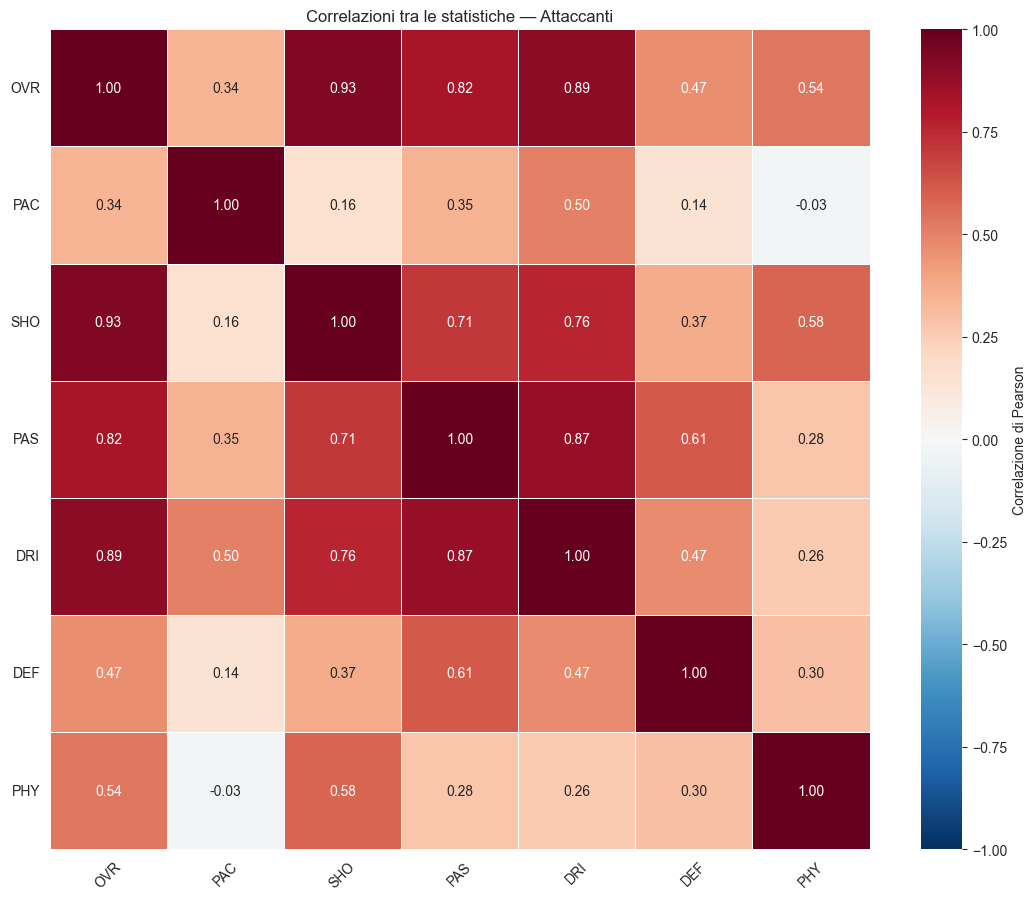

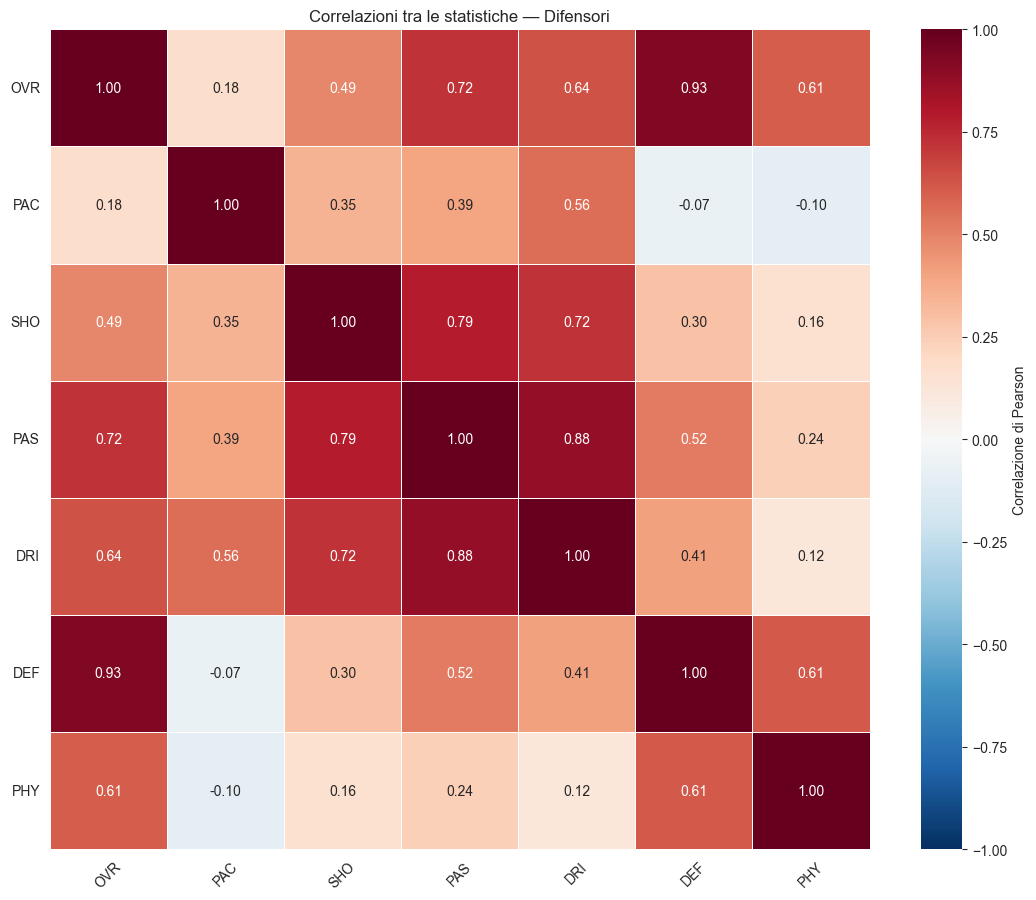

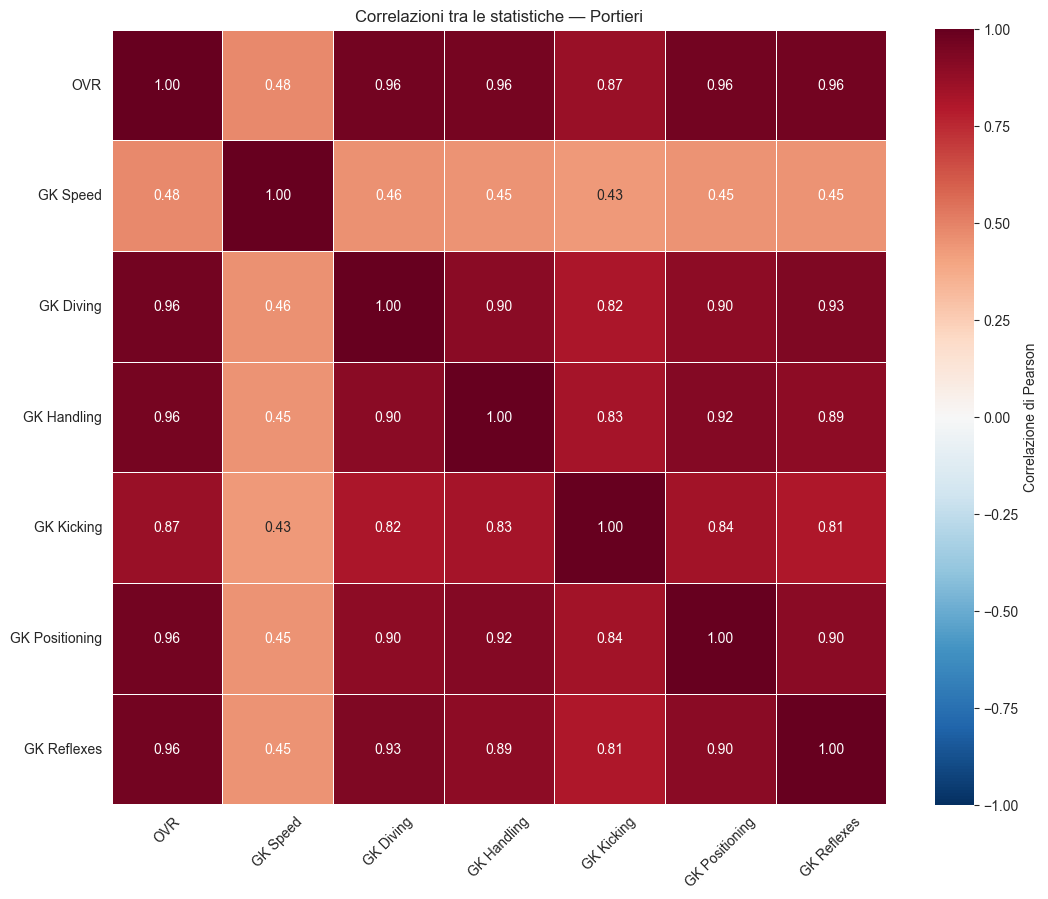

In [6]:
ATTACK_POSITIONS = ['ST', 'LW', 'RW', 'CF']
DEFENCE_POSITIONS = ['CB', 'LB', 'RB', 'LWB', 'RWB']

df_attaccanti = df_movimento[
    df_movimento['Position'].isin(ATTACK_POSITIONS)
]
df_difensori = df_movimento[
    df_movimento['Position'].isin(DEFENCE_POSITIONS)
]

movement_correlation_features = ['OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
goalkeeper_correlation_features = [
    'OVR', 'GK Speed', 'GK Diving', 'GK Handling',
    'GK Kicking', 'GK Positioning', 'GK Reflexes',
]

correlation_matrices = {
    'Attaccanti': df_attaccanti[movement_correlation_features].corr(),
    'Difensori': df_difensori[movement_correlation_features].corr(),
    'Portieri': df_portieri[goalkeeper_correlation_features].corr(),
}

print(f'Attaccanti considerati: {len(df_attaccanti):,}')
print(f'Difensori considerati: {len(df_difensori):,}')
print(f'Portieri considerati: {len(df_portieri):,}')

figure_names = {
    'Attaccanti': '03_correlazioni_attaccanti.png',
    'Difensori': '04_correlazioni_difensori.png',
    'Portieri': '05_correlazioni_portieri.png',
}

for role, correlation_matrix in correlation_matrices.items():
    fig, ax = plt.subplots(figsize=(11, 9))
    sns.heatmap(
        correlation_matrix,
        annot=True,
        fmt='.2f',
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={'label': 'Correlazione di Pearson'},
        ax=ax,
    )
    ax.set_title(f'Correlazioni tra le statistiche — {role}')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)
    fig.tight_layout()
    fig.savefig(
        FIG_DIR / figure_names[role],
        dpi=300,
        bbox_inches='tight',
    )
    plt.show()


#### Interpretazione

Tra gli attaccanti, `OVR` presenta la relazione più forte con `SHO` (circa **0,93**); tra i difensori la relazione più elevata è tra `OVR` e `DEF` (circa **0,93**). Nei portieri, `OVR` è fortemente associato a `GK Reflexes` (circa **0,96**). Questi valori sono plausibili perché la valutazione complessiva riassume anche le abilità specifiche del ruolo.

Le correlazioni negative osservate tra le statistiche dei giocatori di movimento sono molto deboli. Il valore più basso è circa **−0,10** tra `PAC` e `PHY` nei difensori: indica soltanto una lieve tendenza inversa e non una contrapposizione rilevante. La scala completa è mantenuta per rappresentare correttamente il segno delle relazioni e rendere confrontabili le tre matrici.


#### Altezza, peso e ruolo

Le colonne `Height` e `Weight` riportano la stessa misura sia nel sistema metrico sia in quello imperiale. Per l'analisi vengono estratti i valori in centimetri e chilogrammi, mantenendo inalterate le colonne originali. Le relazioni sono esaminate prima per macro-ruolo e poi attraverso il coefficiente di Pearson. Anche in questo caso si parla di associazione statistica e non di un rapporto di causa-effetto.

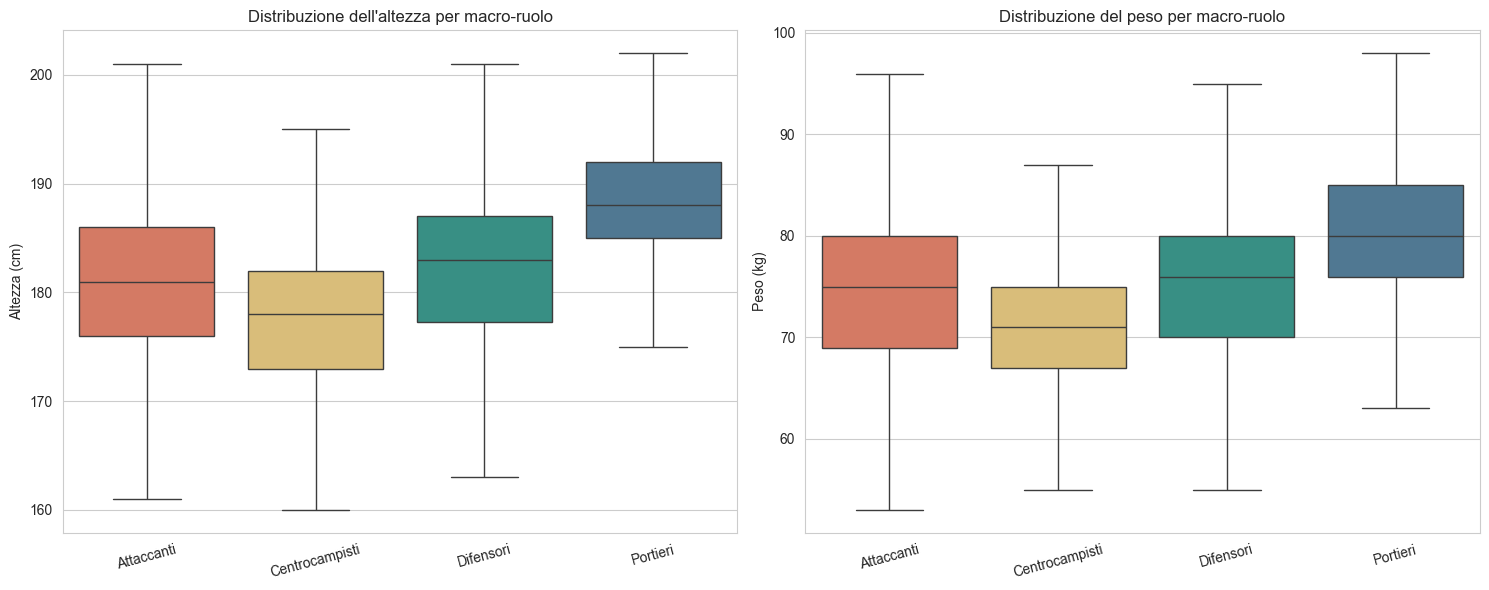

Mediane per macro-ruolo:


,Altezza (cm),Peso (kg)
Macro-ruolo,,
Attaccanti,181.0,75.0
Centrocampisti,178.0,71.0
Difensori,183.0,76.0
Portieri,188.0,80.0


In [7]:
# --- PREPARAZIONE DI ALTEZZA, PESO E MACRO-RUOLO ---

df_fisico_movimento = df_movimento.copy()
df_fisico_portieri = df_portieri.copy()

for dataframe in [df_fisico_movimento, df_fisico_portieri]:
    dataframe['Height_cm'] = (
        dataframe['Height'].str.extract(r'(\d+)cm')[0].astype(int)
    )
    dataframe['Weight_kg'] = (
        dataframe['Weight'].str.extract(r'(\d+)kg')[0].astype(int)
    )

ROLE_POSITIONS = {
    'Attaccanti': ['ST', 'LW', 'RW'],
    'Centrocampisti': ['CAM', 'CM', 'CDM', 'LM', 'RM'],
    'Difensori': ['CB', 'LB', 'RB'],
}
position_to_role = {
    position: role
    for role, positions in ROLE_POSITIONS.items()
    for position in positions
}
df_fisico_movimento['Macro-ruolo'] = (
    df_fisico_movimento['Position'].map(position_to_role)
)
df_fisico_portieri['Macro-ruolo'] = 'Portieri'

if df_fisico_movimento['Macro-ruolo'].isna().any():
    posizioni_non_mappate = sorted(
        df_fisico_movimento.loc[
            df_fisico_movimento['Macro-ruolo'].isna(), 'Position'
        ].unique()
    )
    raise ValueError(f'Posizioni non mappate: {posizioni_non_mappate}')

df_fisico_ruoli = pd.concat(
    [
        df_fisico_movimento[['Macro-ruolo', 'Height_cm', 'Weight_kg']],
        df_fisico_portieri[['Macro-ruolo', 'Height_cm', 'Weight_kg']],
    ],
    ignore_index=True,
)

role_order = ['Attaccanti', 'Centrocampisti', 'Difensori', 'Portieri']
role_palette = ['#E76F51', '#E9C46A', '#2A9D8F', '#457B9D']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(
    data=df_fisico_ruoli, x='Macro-ruolo', y='Height_cm',
    order=role_order, palette=role_palette, showfliers=False, ax=axes[0]
)
axes[0].set_title("Distribuzione dell'altezza per macro-ruolo")
axes[0].set_xlabel('')
axes[0].set_ylabel('Altezza (cm)')

sns.boxplot(
    data=df_fisico_ruoli, x='Macro-ruolo', y='Weight_kg',
    order=role_order, palette=role_palette, showfliers=False, ax=axes[1]
)
axes[1].set_title('Distribuzione del peso per macro-ruolo')
axes[1].set_xlabel('')
axes[1].set_ylabel('Peso (kg)')

for ax in axes:
    ax.tick_params(axis='x', rotation=15)

fig.tight_layout()
fig.savefig(
    FIG_DIR / '20_altezza_peso_per_ruolo.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

print('Mediane per macro-ruolo:')
display(
    df_fisico_ruoli.groupby('Macro-ruolo')[['Height_cm', 'Weight_kg']]
    .median()
    .reindex(role_order)
    .rename(columns={'Height_cm': 'Altezza (cm)', 'Weight_kg': 'Peso (kg)'})
)

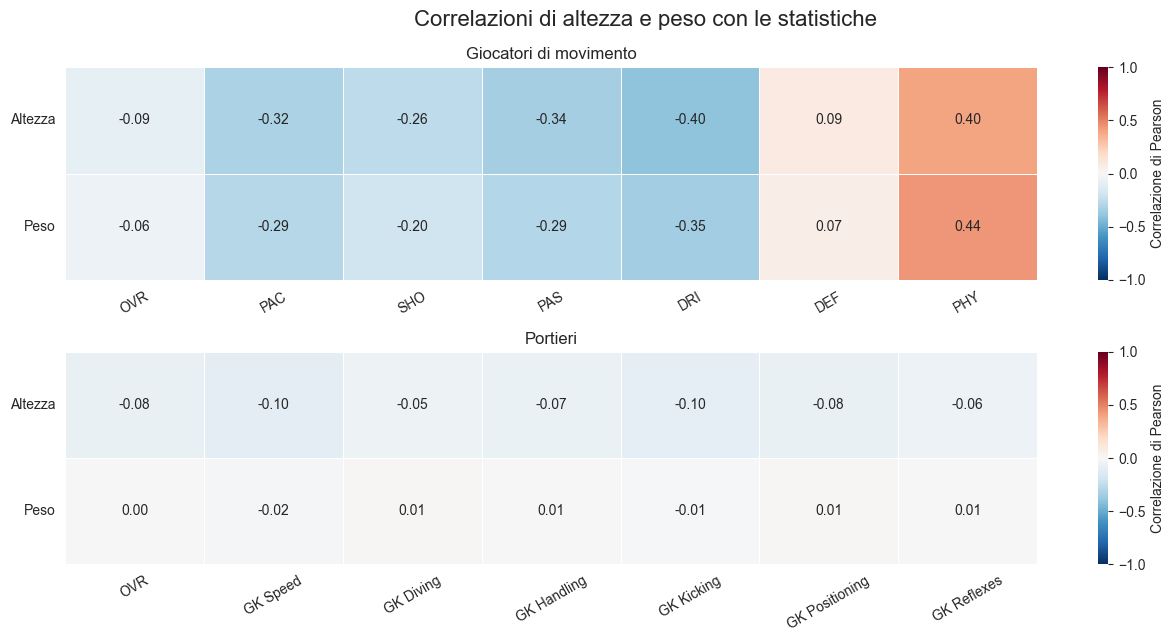

In [8]:
# --- CORRELAZIONI COMPLESSIVE CON ALTEZZA E PESO ---

movement_physical_features = ['OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
goalkeeper_physical_features = [
    'OVR', 'GK Speed', 'GK Diving', 'GK Handling',
    'GK Kicking', 'GK Positioning', 'GK Reflexes'
]
physical_variables = ['Height_cm', 'Weight_kg']

corr_fisiche_movimento = (
    df_fisico_movimento[physical_variables + movement_physical_features]
    .corr()
    .loc[physical_variables, movement_physical_features]
    .rename(index={'Height_cm': 'Altezza', 'Weight_kg': 'Peso'})
)
corr_fisiche_portieri = (
    df_fisico_portieri[physical_variables + goalkeeper_physical_features]
    .corr()
    .loc[physical_variables, goalkeeper_physical_features]
    .rename(index={'Height_cm': 'Altezza', 'Weight_kg': 'Peso'})
)

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
for ax, matrix, title in [
    (axes[0], corr_fisiche_movimento, 'Giocatori di movimento'),
    (axes[1], corr_fisiche_portieri, 'Portieri'),
]:
    sns.heatmap(
        matrix, annot=True, fmt='.2f', cmap='RdBu_r',
        center=0, vmin=-1, vmax=1, linewidths=0.5,
        cbar_kws={'label': 'Correlazione di Pearson'}, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('Correlazioni di altezza e peso con le statistiche', fontsize=16)
fig.tight_layout()
fig.savefig(
    FIG_DIR / '21_correlazioni_altezza_peso.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

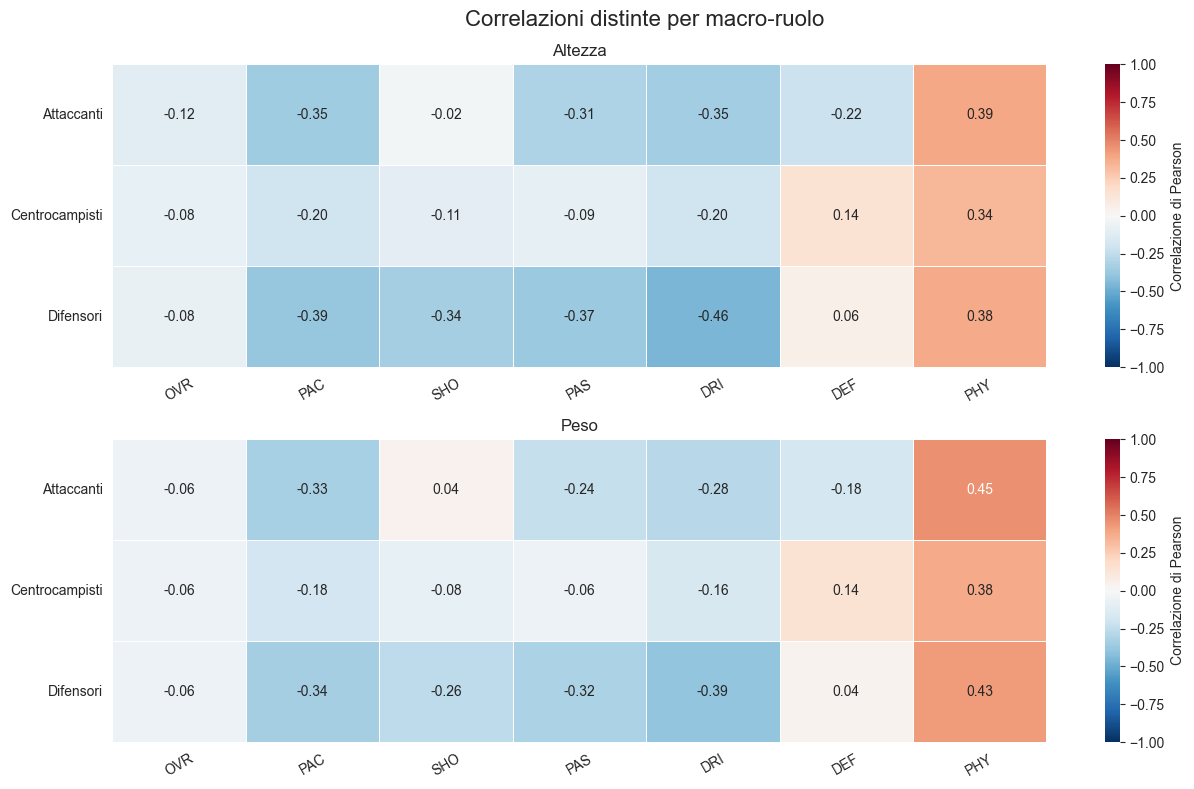

In [9]:
# --- CORRELAZIONI CALCOLATE ALL'INTERNO DEI MACRO-RUOLI ---

corr_altezza_ruolo = pd.DataFrame({
    role: gruppo[movement_physical_features].corrwith(gruppo['Height_cm'])
    for role, gruppo in df_fisico_movimento.groupby('Macro-ruolo')
}).T.reindex(role_order[:-1])

corr_peso_ruolo = pd.DataFrame({
    role: gruppo[movement_physical_features].corrwith(gruppo['Weight_kg'])
    for role, gruppo in df_fisico_movimento.groupby('Macro-ruolo')
}).T.reindex(role_order[:-1])

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
for ax, matrix, title in [
    (axes[0], corr_altezza_ruolo, 'Altezza'),
    (axes[1], corr_peso_ruolo, 'Peso'),
]:
    sns.heatmap(
        matrix, annot=True, fmt='.2f', cmap='RdBu_r',
        center=0, vmin=-1, vmax=1, linewidths=0.5,
        cbar_kws={'label': 'Correlazione di Pearson'}, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('Correlazioni distinte per macro-ruolo', fontsize=16)
fig.tight_layout()
fig.savefig(
    FIG_DIR / '22_correlazioni_fisiche_per_ruolo.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

#### Interpretazione delle caratteristiche fisiche

Tra i giocatori di movimento, il peso presenta una correlazione positiva con `PHY` (circa **0,44**), mentre l'altezza è associata positivamente alla stessa statistica (circa **0,40**). Le relazioni più evidenti di segno negativo riguardano `DRI`: circa **-0,40** per l'altezza e **-0,35** per il peso. L'associazione con `OVR` è invece molto debole, per cui una corporatura più imponente non corrisponde automaticamente a una valutazione complessiva maggiore.

Il controllo per macro-ruolo conferma che una parte delle differenze dipende dalla posizione, ma le tendenze principali rimangono visibili anche all'interno dei gruppi. Per esempio, la correlazione tra altezza e `DRI` varia da circa **-0,20** nei centrocampisti a **-0,46** nei difensori; quella tra peso e `PHY` varia da circa **0,38** nei centrocampisti a **0,45** negli attaccanti. Nei portieri, invece, tutte le associazioni tra altezza, peso e statistiche specifiche risultano molto deboli, con valori assoluti non superiori a circa **0,10**.

### PLAYSTYLE

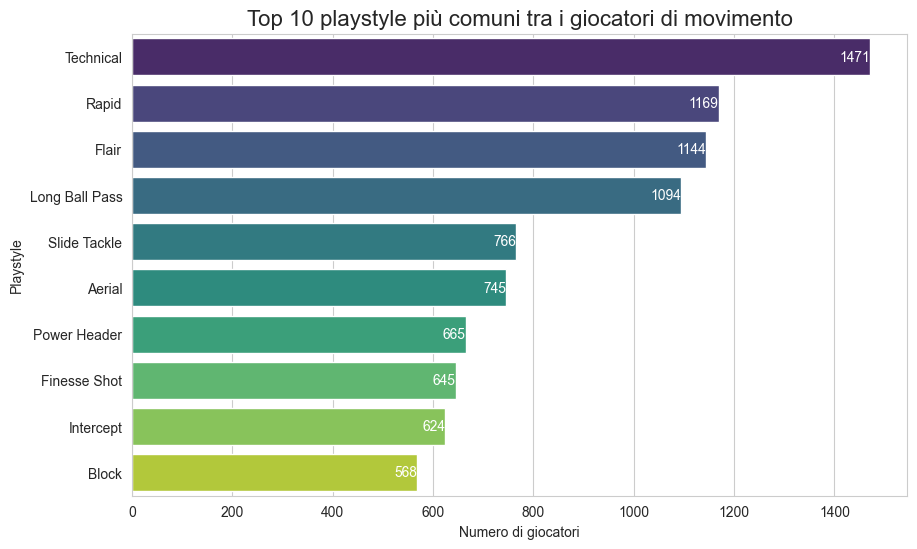

In [10]:
# Top 10 playing styles

playing_style = df_movimento['play style'].str.split(', ')
playing_style = playing_style.explode()
playing_style = playing_style.value_counts()
top_styles = playing_style.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_styles.values, y=top_styles.index, palette='viridis')
plt.title('Top 10 playstyle più comuni tra i giocatori di movimento', fontsize=16)
for x,y in enumerate(top_styles.values):
    plt.text(y, x, str(y), ha='right', color='white', va='center')
plt.xlabel('Numero di giocatori')
plt.ylabel('Playstyle')
plt.savefig(FIG_DIR / '19_top_10_playstyle.png', dpi=300, bbox_inches='tight')
plt.show()

### ANALISI DELL'ETÀ

L'età viene confrontata tra giocatori di movimento e portieri. Poiché i due gruppi hanno numerosità molto diverse, il confronto principale utilizza distribuzioni percentuali e non conteggi assoluti. La tabella dei conteggi per età viene mantenuta completa; gli eventuali filtri utilizzati nei grafici vengono applicati soltanto a copie dedicate.


In [11]:
age_data = pd.concat([
    df_movimento[['Age']].assign(Tipo='Giocatori di movimento'),
    df_portieri[['Age']].assign(Tipo='Portieri'),
], ignore_index=True)

age_counts = pd.DataFrame({
    'Giocatori di movimento': df_movimento['Age'].value_counts(),
    'Portieri': df_portieri['Age'].value_counts(),
}).fillna(0).astype(int).sort_index()

age_counts['Totale'] = age_counts.sum(axis=1)
age_counts['Percentuale portieri'] = (
    age_counts['Portieri'] / age_counts['Totale'] * 100
)

age_summary = (
    age_data.groupby('Tipo')['Age']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .rename(columns={
        'count': 'Giocatori',
        'mean': 'Media',
        'median': 'Mediana',
        'min': 'Minimo',
        'max': 'Massimo',
    })
)

display(age_summary.style.format({
    'Giocatori': '{:,.0f}',
    'Media': '{:.2f}',
    'Mediana': '{:.0f}',
    'Minimo': '{:.0f}',
    'Massimo': '{:.0f}',
}))

print(
    f"Intervallo completo considerato: "
    f"{age_counts.index.min()}-{age_counts.index.max()} anni"
)


,Giocatori,Media,Mediana,Minimo,Massimo
Tipo,,,,,
Giocatori di movimento,"15,738",25.62,25,17,43
Portieri,"1,999",26.76,26,17,44


Intervallo completo considerato: 17-44 anni


#### Confronto delle distribuzioni

I due pannelli utilizzano come denominatore il totale del rispettivo gruppo. Una barra del 7% nel pannello dei portieri indica quindi che il 7% di tutti i portieri ha quell'età. Le barre di ciascun pannello, considerate complessivamente, sommano al 100%. Questa normalizzazione permette di confrontare la forma delle distribuzioni nonostante la diversa numerosità dei gruppi.


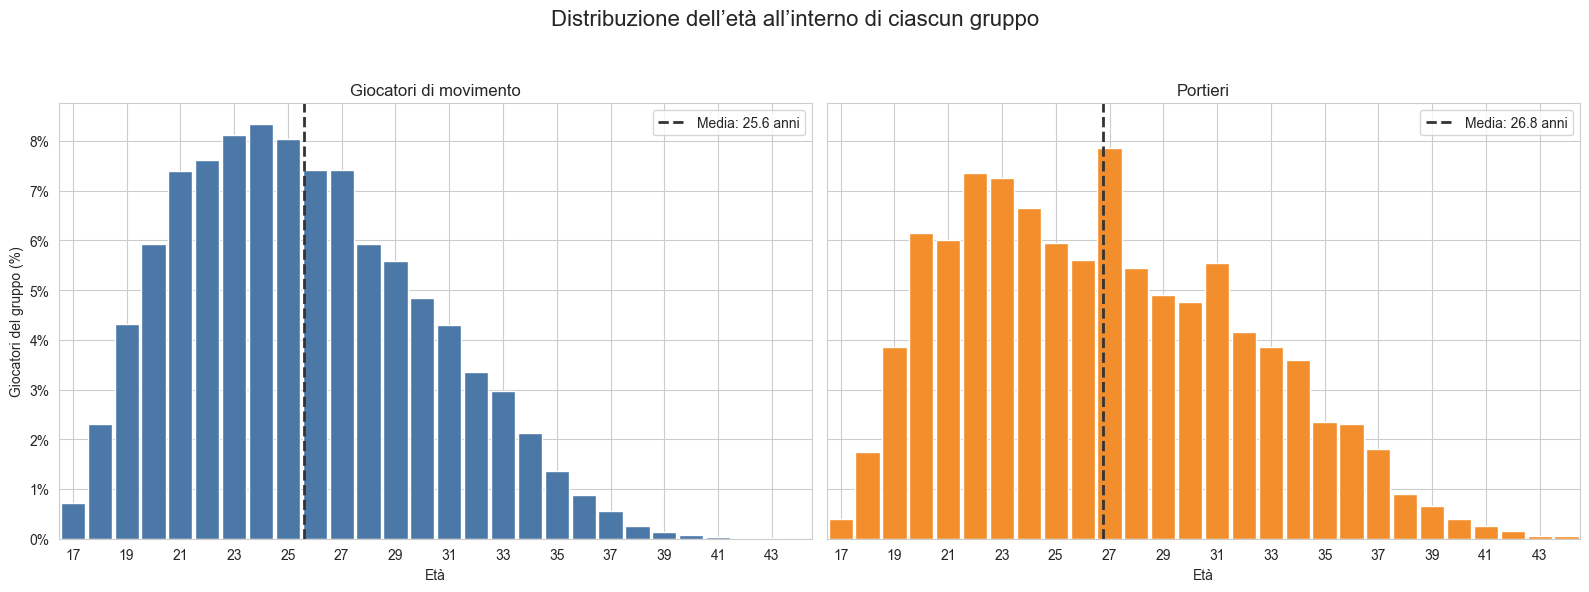

In [12]:
minimum_age = int(age_data['Age'].min())
maximum_age = int(age_data['Age'].max())
ages = np.arange(minimum_age, maximum_age + 1)

movement_age_percentage = (
    df_movimento['Age'].value_counts(normalize=True)
    .reindex(ages, fill_value=0)
    .sort_index() * 100
)
goalkeeper_age_percentage = (
    df_portieri['Age'].value_counts(normalize=True)
    .reindex(ages, fill_value=0)
    .sort_index() * 100
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
distribution_data = [
    ('Giocatori di movimento', movement_age_percentage, '#4c78a8', df_movimento['Age'].mean()),
    ('Portieri', goalkeeper_age_percentage, '#f28e2b', df_portieri['Age'].mean()),
]

for ax, (group_name, percentages, color, mean_age) in zip(axes, distribution_data):
    ax.bar(ages, percentages, color=color, edgecolor='white', width=0.9)
    ax.axvline(
        mean_age, color='#333333', linestyle='--', linewidth=2,
        label=f'Media: {mean_age:.1f} anni'
    )
    ax.set_title(group_name)
    ax.set_xlabel('Età')
    ax.set_xlim(minimum_age - 0.5, maximum_age + 0.5)
    ax.set_xticks(np.arange(minimum_age, maximum_age + 1, 2))
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.legend()

axes[0].set_ylabel('Giocatori del gruppo (%)')
fig.suptitle('Distribuzione dell’età all’interno di ciascun gruppo', fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(
    FIG_DIR / '01_distribuzione_eta_normalizzata.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()


#### Presenza dei portieri alle diverse età

In questo grafico il denominatore cambia: ogni barra rappresenta tutti i giocatori di una determinata età e somma al 100%. La parte arancione indica la percentuale di portieri tra i giocatori di quell'età, mentre la parte blu rappresenta i giocatori di movimento. Tutte le età vengono mantenute; per quelle con meno di 30 osservazioni viene indicata sopra la barra la numerosità disponibile (`n`), perché le relative percentuali sono meno stabili.


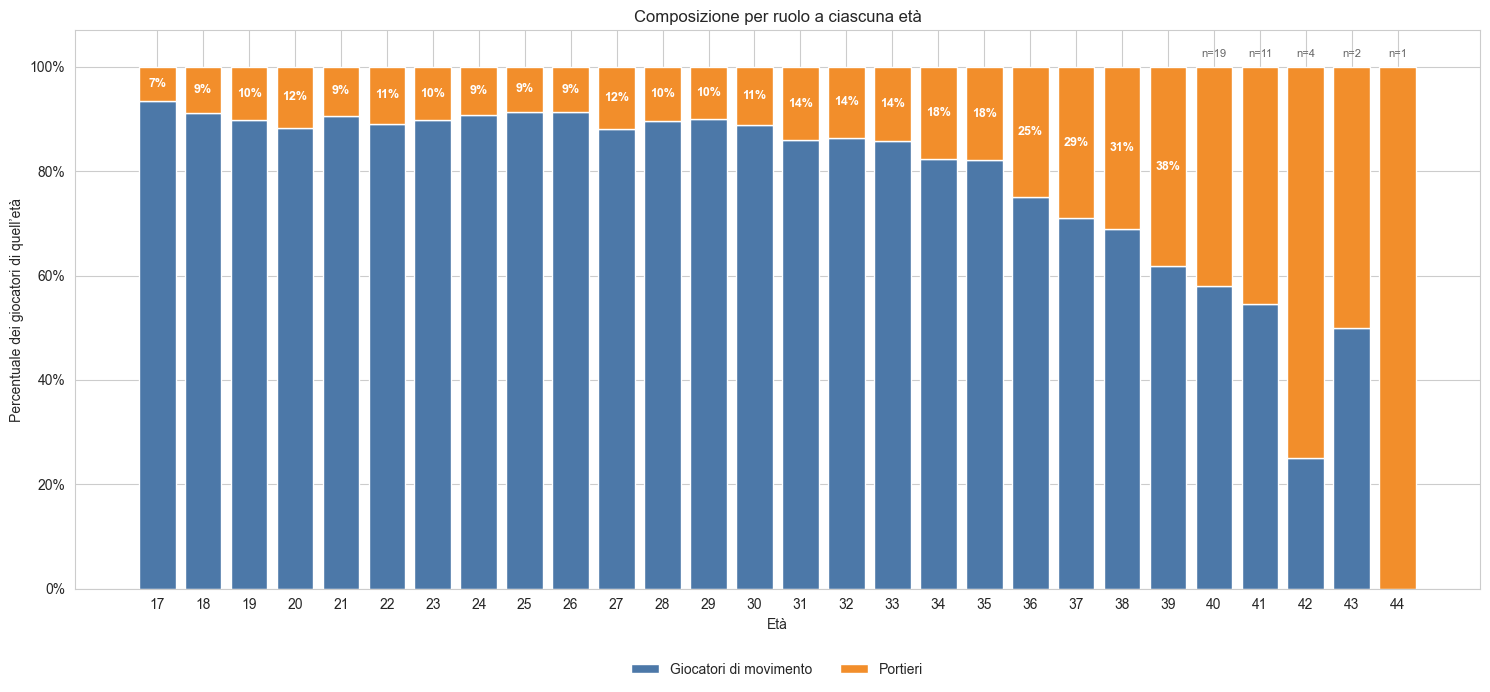

In [13]:
minimum_total_per_age = 30
age_composition = age_counts.copy()
age_composition['Percentuale movimento'] = (
    age_composition['Giocatori di movimento']
    / age_composition['Totale'] * 100
)
age_composition['Percentuale portieri'] = (
    age_composition['Portieri']
    / age_composition['Totale'] * 100
)

reliable_age_counts = age_composition.loc[
    age_composition['Totale'] >= minimum_total_per_age
]
limited_age_counts = age_composition.loc[
    age_composition['Totale'] < minimum_total_per_age
]

fig, ax = plt.subplots(figsize=(15, 7))
ax.bar(
    age_composition.index,
    age_composition['Percentuale movimento'],
    color='#4c78a8',
    label='Giocatori di movimento',
)
ax.bar(
    age_composition.index,
    age_composition['Percentuale portieri'],
    bottom=age_composition['Percentuale movimento'],
    color='#f28e2b',
    label='Portieri',
)

for age, row in reliable_age_counts.iterrows():
    goalkeeper_percentage = row['Percentuale portieri']
    ax.text(
        age, 100 - goalkeeper_percentage / 2,
        f'{goalkeeper_percentage:.0f}%',
        ha='center', va='center', color='white', fontsize=9, fontweight='bold'
    )

for age, row in limited_age_counts.iterrows():
    ax.text(
        age, 101.5, f"n={int(row['Totale'])}",
        ha='center', va='bottom', color='#666666', fontsize=8
    )

ax.set_title('Composizione per ruolo a ciascuna età')
ax.set_xlabel('Età')
ax.set_ylabel('Percentuale dei giocatori di quell’età')
ax.set_xticks(age_composition.index)
ax.set_ylim(0, 107)
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.legend(
    loc='upper center', bbox_to_anchor=(0.5, -0.11),
    ncol=2, frameon=False
)

fig.tight_layout()
fig.savefig(
    FIG_DIR / '02_percentuale_portieri_per_eta.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()


#### Interpretazione

I portieri risultano mediamente più anziani: **26,76 anni** contro **25,62 anni** dei giocatori di movimento; anche la mediana è maggiore, 26 contro 25 anni. Tra le età con almeno 30 osservazioni, la percentuale di portieri sul totale tende inoltre ad aumentare nelle fasce più elevate. Le età meno numerose sono comunque mostrate e la loro numerosità è indicata sopra le barre, perché le percentuali possono cambiare molto in presenza di pochi giocatori.

L'analisi è descrittiva: non dimostra che il ruolo di portiere causi una carriera più lunga, ma evidenzia una diversa distribuzione anagrafica nel dataset FC25.


### CAMPIONATI E NAZIONALITA' PIU' PRESENTI

Analisi Nazionalità e Campionati più presenti...


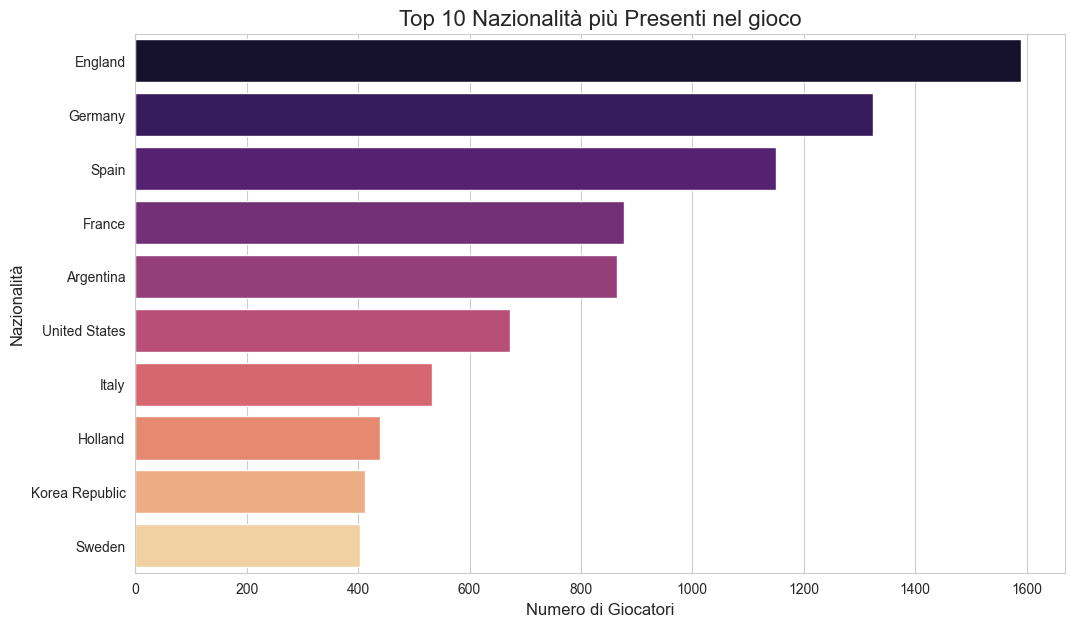

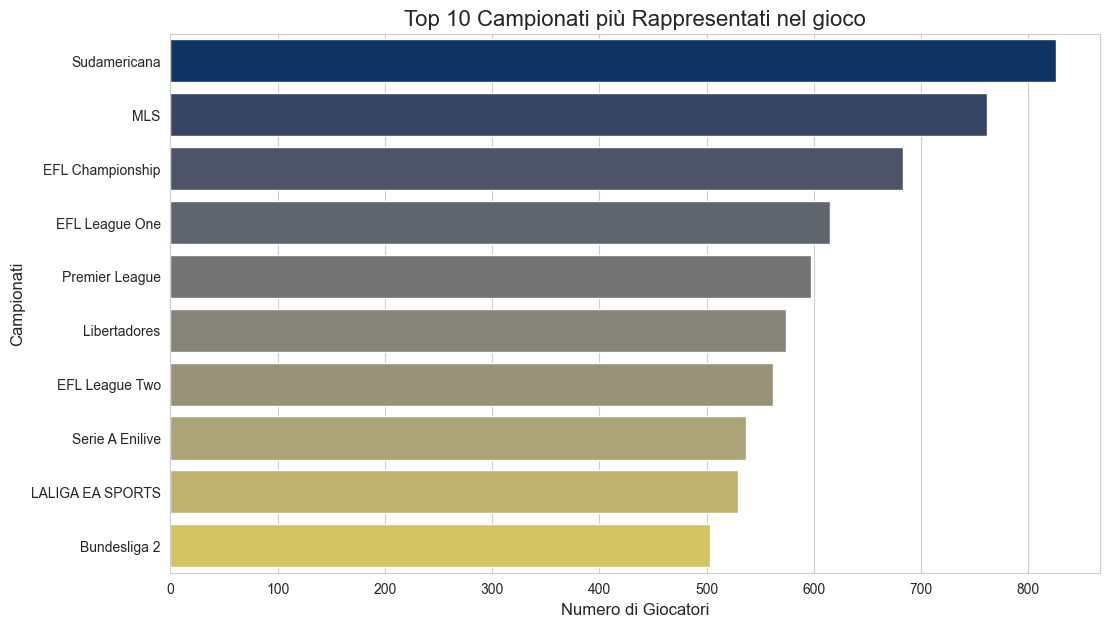

In [14]:
# --- CELLA 16: TOP 10 NAZIONALITÀ E CAMPIONATI ---

print("Analisi Nazionalità e Campionati più presenti...")

# --- 1. Preparazione Dati ---
# Uniamo temporaneamente le colonne 'Nation' e 'League'
# dai nostri due DataFrame puliti per avere il conteggio totale.

all_nations = pd.concat([df_movimento['Nation'], df_portieri['Nation']])
all_leagues = pd.concat([df_movimento['League'], df_portieri['League']])

# --- 2. Analisi Nazionalità ---
# Facciamo un value_counts() e prendiamo le prime 10

top_nations = all_nations.value_counts().head(10)

# Creiamo il grafico a barre orizzontali
plt.figure(figsize=(12, 7))

# Nota: y=index, x=values per il grafico orizzontale

sns.barplot(x=top_nations.values, y=top_nations.index, palette='magma')
plt.title('Top 10 Nazionalità più Presenti nel gioco', fontsize=16)
plt.xlabel('Numero di Giocatori', fontsize=12)
plt.ylabel('Nazionalità', fontsize=12)
plt.show()

# --- 3. Analisi Campionati ---
# Facciamo un value_counts() e prendiamo le prime 10

top_leagues = all_leagues.value_counts().head(10)

# Creiamo il grafico a barre orizzontali
plt.figure(figsize=(12, 7))

sns.barplot(x=top_leagues.values, y=top_leagues.index, palette='cividis')
plt.title('Top 10 Campionati più Rappresentati nel gioco', fontsize=16)
plt.xlabel('Numero di Giocatori', fontsize=12)
plt.ylabel('Campionati', fontsize=12)
plt.show()

### CONFRONTO TRA GIOCATORI

In [15]:
# mi serviva per vedere come fossero scritti i nomi dei giocatori

df_movimento.head()

,Name,OVR,PAC,SHO,PAS,DRI,DEF,PHY,Acceleration,Sprint Speed,...,Skill moves,Preferred foot,Height,Weight,Alternative positions,Age,Nation,League,Team,play style
0,Kylian Mbappé,91,97,90,80,92,36,78,97,97,...,5,Right,"182cm / 6'0""",75kg / 165lb,LW,25,France,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Acrobatic, Finesse Shot, Flair, R..."
1,Rodri,91,66,80,86,84,87,85,65,66,...,3,Right,"191cm / 6'3""",82kg / 181lb,CM,28,Spain,Premier League,Manchester City,"Tiki Taka+, Aerial, Bruiser, Long Ball Pass, P..."
2,Erling Haaland,91,88,92,70,81,45,88,80,94,...,3,Left,"195cm / 6'5""",94kg / 207lb,NaN,24,Norway,Premier League,Manchester City,"Acrobatic+, Bruiser, Power Header, Power Shot,..."
3,Jude Bellingham,90,80,87,83,88,78,83,81,80,...,4,Right,"186cm / 6'1""",75kg / 165lb,CM,21,England,LALIGA EA SPORTS,Real Madrid,"Relentless+, Flair, Intercept, Slide Tackle, T..."
4,Vini Jr.,90,95,84,81,91,29,69,95,95,...,5,Right,"176cm / 5'9""",73kg / 161lb,"ST, LM",24,Brazil,LALIGA EA SPORTS,Real Madrid,"Quick Step+, Chip Shot, Finesse Shot, First To..."


In [16]:
# --- ESTRAZIONE DATI: MBAPPÉ VS HAALAND ---

player_1_name = 'Kylian Mbappé'
player_2_name = 'Erling Haaland'

player_1_stats = select_player(player_1_name)
player_2_stats = select_player(player_2_name)

print('--- Dati trovati ---')
print(f"Giocatore 1: {player_1_stats['Name']} (OVR: {player_1_stats['OVR']})")
print(f"Giocatore 2: {player_2_stats['Name']} (OVR: {player_2_stats['OVR']})")


--- Dati trovati ---
Giocatore 1: Kylian Mbappé (OVR: 91)
Giocatore 2: Erling Haaland (OVR: 91)


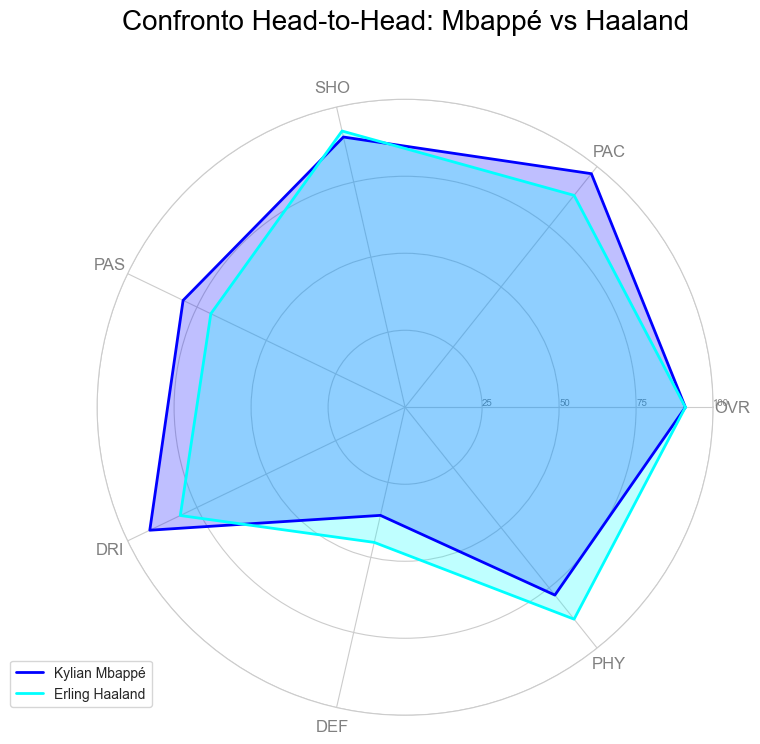

In [17]:
# --- CELLA 19: GRAFICO RADAR (CONFRONTO STATS BASE) ---

# 1. Definiamo le categorie (le 6 stats base)
categories = ['OVR' ,'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
N = len(categories)

# 2. Prepariamo i valori per il Giocatore 1 (Mbappé)
values_p1 = player_1_stats[categories].values.flatten().tolist()
values_p1 += values_p1[:1] # Chiudiamo il cerchio (aggiungiamo il primo valore alla fine)

# 3. Prepariamo i valori per il Giocatore 2 (Haaland)
values_p2 = player_2_stats[categories].values.flatten().tolist()
values_p2 += values_p2[:1] # Chiudiamo il cerchio

# 4. Calcoliamo gli angoli per ogni asse
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1] # Chiudiamo il cerchio

# 5. Creazione del Grafico
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# 6. Disegniamo gli assi
plt.xticks(angles[:-1], categories, color='grey', size=12)

# 7. Disegniamo i "livelli" (es. 25, 50, 75, 100)
ax.set_rlabel_position(0)
plt.yticks([25, 50, 75, 100], ["25", "50", "75", "100"], color="grey", size=7)
plt.ylim(0, 100) # Assicuriamoci che la scala sia 0-100

# 8. Disegniamo il poligono del Giocatore 1 (Mbappé)
ax.plot(angles, values_p1, linewidth=2, linestyle='solid', label=player_1_stats['Name'], color='blue')
ax.fill(angles, values_p1, 'blue', alpha=0.25)

# 9. Disegniamo il poligono del Giocatore 2 (Haaland)
ax.plot(angles, values_p2, linewidth=2, linestyle='solid', label=player_2_stats['Name'], color='cyan')
ax.fill(angles, values_p2, 'cyan', alpha=0.25)

# 10. Aggiungiamo titolo e legenda
plt.title('Confronto Head-to-Head: Mbappé vs Haaland', size=20, color='black', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

fig.savefig(FIG_DIR / '12_mbappe_haaland_radar.png', dpi=300, bbox_inches='tight')
plt.show()


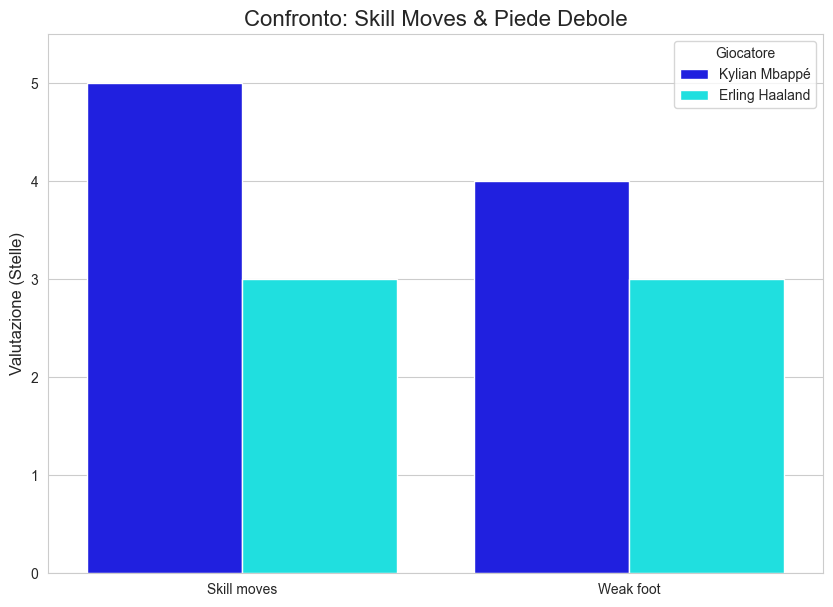

In [18]:
# --- CELLA 20: Confronto Skill/Piede Debole (Grafico a Barre Raggruppato) ---

# 1. Estrarre i dati che ci servono in un unico DataFrame
df_compare_stars = pd.DataFrame([
    player_1_stats[['Name', 'Skill moves', 'Weak foot']],
    player_2_stats[['Name', 'Skill moves', 'Weak foot']]
])

# 2. Riformattare i Dati (da "Largo" a "Lungo")
#    Questo è il passaggio chiave per il raggruppamento
#    Trasforma il DataFrame in un formato che Seaborn capisce
df_long = df_compare_stars.melt(id_vars=['Name'], 
                                value_vars=['Skill moves', 'Weak foot'], 
                                var_name='Statistica', 
                                value_name='Stelle')

# print("--- Dati in formato Lungo (per il grafico) ---")
# print(df_long.to_markdown(index=False))
# Output (esempio):
# | Name             | Statistica    | Stelle |
# |:-----------------|:--------------|:-------|
# | Kylian Mbappé    | Skill moves   | 5      |
# | Erling Haaland   | Skill moves   | 3      |
# | Kylian Mbappé    | Weak foot     | 4      |
# | Erling Haaland   | Weak foot     | 3      |


# 3. Creazione del Grafico
plt.figure(figsize=(10, 7))

# Usiamo sns.barplot()
# x='Statistica' -> Crea i due gruppi sull'asse X
# y='Stelle'     -> L'altezza della barra
# hue='Name'       -> Il colore (raggruppa le barre per giocatore)
sns.barplot(data=df_long, x='Statistica', y='Stelle', hue='Name', palette=['blue', 'cyan'])

plt.title('Confronto: Skill Moves & Piede Debole', fontsize=16)
plt.xlabel('') # L'etichetta 'Statistica' è già chiara
plt.ylabel('Valutazione (Stelle)', fontsize=12)

# Impostiamo l'asse Y per mostrare chiaramente la scala 1-5
plt.yticks(ticks=range(0, 6)) # Mostra etichette 0, 1, 2, 3, 4, 5
plt.ylim(0, 5.5) # Lascia un po' di spazio sopra il 5

plt.legend(title='Giocatore')
plt.savefig(FIG_DIR / '13_mbappe_haaland_skill_piede_debole.png', dpi=300, bbox_inches='tight')
plt.show()

### CR7 VS MESSI

In [19]:
# --- ESTRAZIONE DATI: RONALDO VS MESSI ---

player_3_name = 'Cristiano Ronaldo'
player_4_name = 'Lionel Messi'

player_3_stats = select_player(player_3_name)
player_4_stats = select_player(player_4_name)

print('--- Dati trovati ---')
print(f"Giocatore 1: {player_3_stats['Name']} (OVR: {player_3_stats['OVR']})")
print(f"Giocatore 2: {player_4_stats['Name']} (OVR: {player_4_stats['OVR']})")


--- Dati trovati ---
Giocatore 1: Cristiano Ronaldo (OVR: 86)
Giocatore 2: Lionel Messi (OVR: 88)


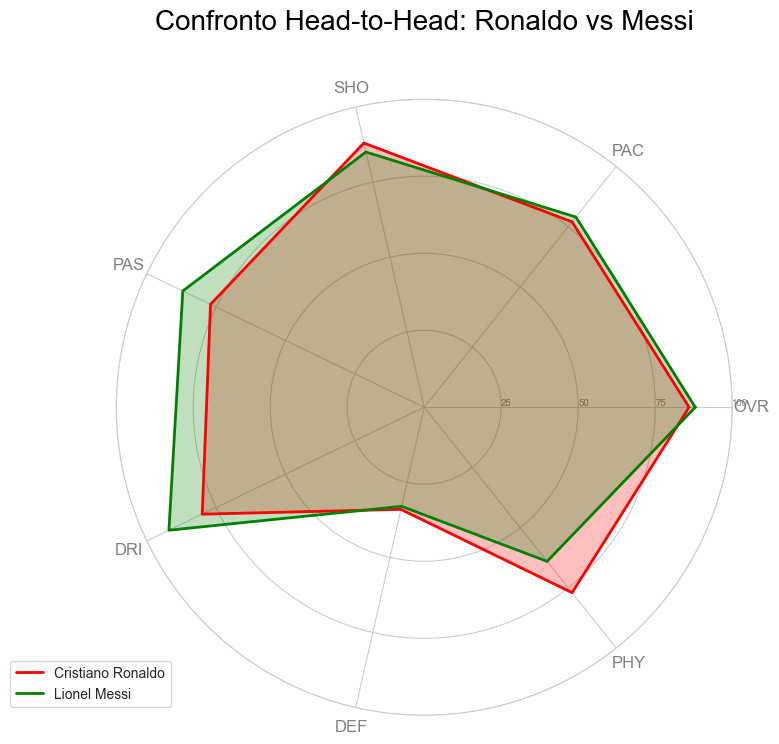

In [20]:
# --- CELLA 22: GRAFICO RADAR (CONFRONTO STATS BASE) ---

categories = ['OVR' ,'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
N = len(categories)

# 2. Prepariamo i valori per il Giocatore 1 (Ronaldo)
values_p3 = player_3_stats[categories].values.flatten().tolist()
values_p3 += values_p3[:1] # Chiudiamo il cerchio 

# 3. Prepariamo i valori per il Giocatore 2 (Messi)
values_p4 = player_4_stats[categories].values.flatten().tolist()
values_p4 += values_p4[:1] # Chiudiamo il cerchio   

# 4. Calcoliamo gli angoli per ogni asse
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1] # Chiudiamo il cerchio

# 5. Creazione del Grafico
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

# 6. Disegniamo gli assi
plt.xticks(angles[:-1], categories, color='grey', size=12)

# 7. Disegniamo i "livelli" (es. 25, 50, 75, 100)
ax.set_rlabel_position(0)
plt.yticks([25, 50, 75, 100], ["25", "50", "75", "100"], color="grey", size=7)
plt.ylim(0, 100) # Assicuriamoci che la scala sia 0-100

# 8. Disegniamo il poligono del Giocatore 1 (Ronaldo)
ax.plot(angles, values_p3, linewidth=2, linestyle='solid', label=player_3_stats['Name'], color='red')
ax.fill(angles, values_p3, 'red', alpha=0.25)   

# 9. Disegniamo il poligono del Giocatore 2 (Messi)
ax.plot(angles, values_p4, linewidth=2, linestyle='solid', label=player_4_stats['Name'], color='green')
ax.fill(angles, values_p4, 'green', alpha=0.25)

# 10. Aggiungiamo titolo e legenda
plt.title('Confronto Head-to-Head: Ronaldo vs Messi', size=20, color='black', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))   

fig.savefig(FIG_DIR / '14_ronaldo_messi_radar.png', dpi=300, bbox_inches='tight')
plt.show()


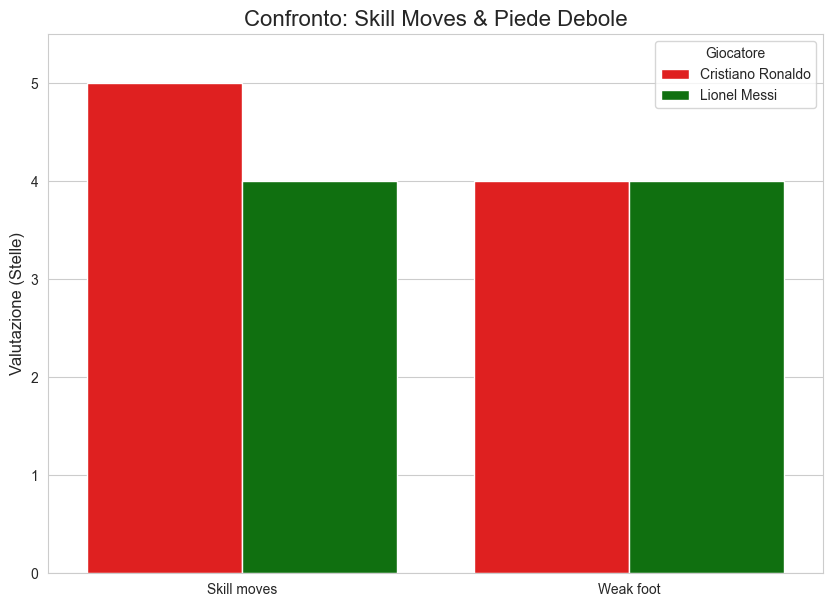

In [21]:
# --- CELLA 20: Confronto Skill/Piede Debole (Grafico a Barre Raggruppato) ---

df_compare_stars = pd.DataFrame([
    player_3_stats[['Name', 'Skill moves', 'Weak foot']],
    player_4_stats[['Name', 'Skill moves', 'Weak foot']]
])

# 2. Riformattare i Dati (da "Largo" a "Lungo")
df_long2 = df_compare_stars.melt(id_vars='Name',
                                 value_vars=['Skill moves', 'Weak foot'],
                                 var_name='Statistica',
                                 value_name='Stelle')

# 3. Creazione del Grafico
plt.figure(figsize=(10,7))
sns.barplot(data=df_long2, x='Statistica', y='Stelle', hue='Name', palette=['red', 'green'])
plt.title('Confronto: Skill Moves & Piede Debole', fontsize=16)
plt.xlabel('') # L'etichetta 'Statistica' è già chiara
plt.ylabel('Valutazione (Stelle)', fontsize=12) 
plt.yticks(ticks=range(0, 6)) # Mostra etichette 0, 1, 2, 3, 4, 5
plt.ylim(0, 5.5) # Lascia un po' di spazio sopra il 5
plt.legend(title='Giocatore')
plt.savefig(FIG_DIR / '15_ronaldo_messi_skill_piede_debole.png', dpi=300, bbox_inches='tight')
plt.show()

### SALAH VS VAN DIJK

Il confronto mette a paragone un attaccante e un difensore con lo stesso valore complessivo (`OVR = 89`), per mostrare come la valutazione generale possa derivare da caratteristiche molto diverse e coerenti con il ruolo.

In [22]:
# --- ESTRAZIONE DATI: SALAH VS VAN DIJK ---

player_5_name = 'Mohamed Salah'
player_6_name = 'Virgil van Dijk'

player_5_stats = select_player(player_5_name)
player_6_stats = select_player(player_6_name)

if player_5_stats['OVR'] != player_6_stats['OVR']:
    raise ValueError('I due giocatori non hanno lo stesso OVR nel dataset.')

print('--- Dati trovati ---')
print(
    f"Giocatore 1: {player_5_stats['Name']} "
    f"({player_5_stats['Position']}, OVR: {player_5_stats['OVR']})"
)
print(
    f"Giocatore 2: {player_6_stats['Name']} "
    f"({player_6_stats['Position']}, OVR: {player_6_stats['OVR']})"
)

--- Dati trovati ---
Giocatore 1: Mohamed Salah (RW, OVR: 89)
Giocatore 2: Virgil van Dijk (CB, OVR: 89)


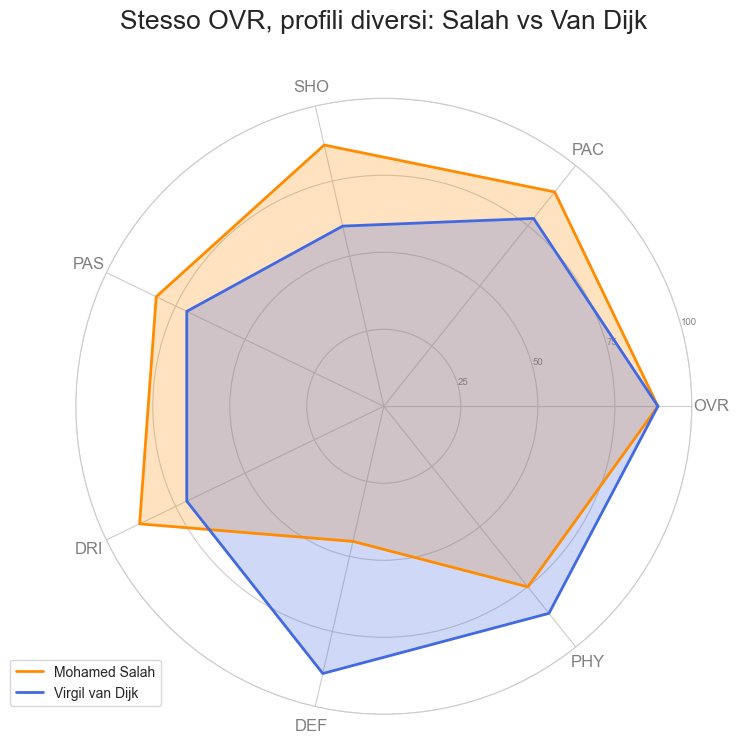

In [23]:
# --- GRAFICO RADAR: SALAH VS VAN DIJK ---

categories = ['OVR', 'PAC', 'SHO', 'PAS', 'DRI', 'DEF', 'PHY']
N = len(categories)

values_p5 = player_5_stats[categories].values.flatten().tolist()
values_p5 += values_p5[:1]
values_p6 = player_6_stats[categories].values.flatten().tolist()
values_p6 += values_p6[:1]

angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
plt.xticks(angles[:-1], categories, color='grey', size=12)
ax.set_rlabel_position(15)
plt.yticks([25, 50, 75, 100], ['25', '50', '75', '100'], color='grey', size=7)
plt.ylim(0, 100)

ax.plot(
    angles, values_p5, linewidth=2, linestyle='solid',
    label=player_5_stats['Name'], color='darkorange'
)
ax.fill(angles, values_p5, color='darkorange', alpha=0.25)
ax.plot(
    angles, values_p6, linewidth=2, linestyle='solid',
    label=player_6_stats['Name'], color='royalblue'
)
ax.fill(angles, values_p6, color='royalblue', alpha=0.25)

plt.title('Stesso OVR, profili diversi: Salah vs Van Dijk', size=19, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(0.15, 0.10))
fig.savefig(FIG_DIR / '17_salah_van_dijk_radar.png', dpi=300, bbox_inches='tight')
plt.show()

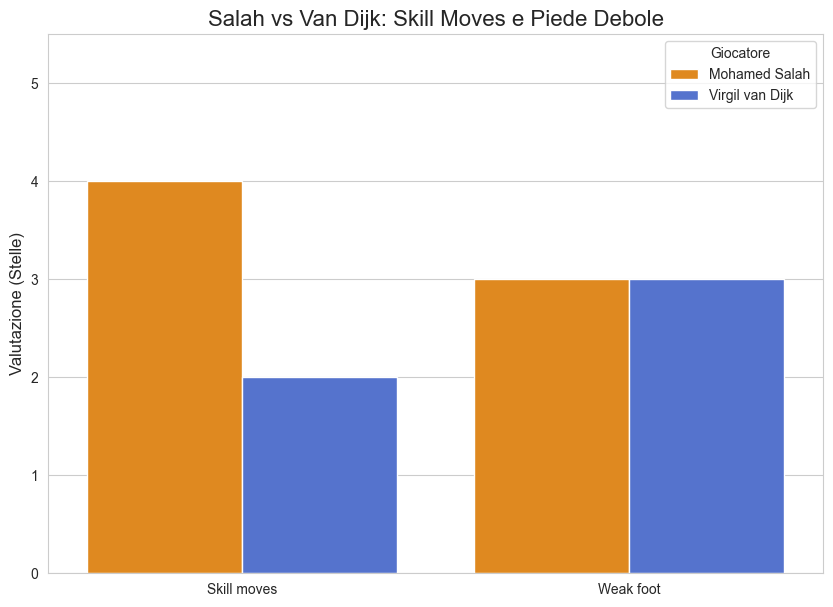

In [24]:
# --- CONFRONTO SKILL MOVES E PIEDE DEBOLE ---

df_compare_stars3 = pd.DataFrame([
    player_5_stats[['Name', 'Skill moves', 'Weak foot']],
    player_6_stats[['Name', 'Skill moves', 'Weak foot']]
])

df_long3 = df_compare_stars3.melt(
    id_vars='Name',
    value_vars=['Skill moves', 'Weak foot'],
    var_name='Statistica',
    value_name='Stelle'
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=df_long3, x='Statistica', y='Stelle', hue='Name',
    palette=['darkorange', 'royalblue']
)
plt.title('Salah vs Van Dijk: Skill Moves e Piede Debole', fontsize=16)
plt.xlabel('')
plt.ylabel('Valutazione (Stelle)', fontsize=12)
plt.yticks(ticks=range(0, 6))
plt.ylim(0, 5.5)
plt.legend(title='Giocatore')
plt.savefig(
    FIG_DIR / '18_salah_van_dijk_skill_piede_debole.png',
    dpi=300, bbox_inches='tight'
)
plt.show()